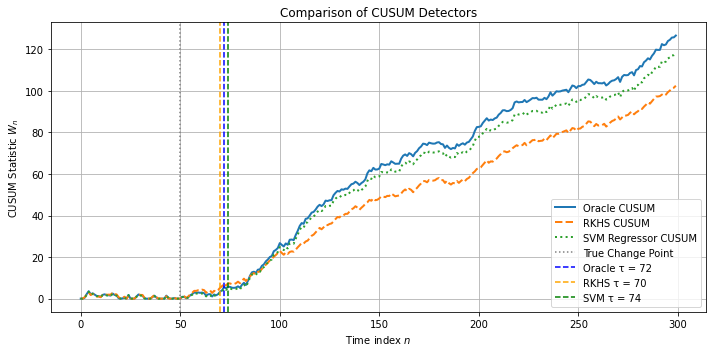

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.svm import SVR
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize
import os

# Oracle CUSUM
class OracleCUSUM:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.threshold = threshold

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            llr = np.log(self.f1(stream[n]) / self.f0(stream[n]))
            W[n] = max(0, W[n - 1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# RKHS-based Estimator
class RKHSLikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None

    def _compute_kernel_matrices(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        return K_PP, K_QP

    def _loss(self, alpha, K_PP, K_QP):
        g_q = K_QP @ alpha
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        term_q = np.mean(g_q)
        term_p = -np.mean(np.log(g_p))
        reg = 0.5 * self.lambda_reg * (alpha @ K_PP @ alpha)
        return term_q + term_p + reg

    def _grad(self, alpha, K_PP, K_QP):
        n_p = K_PP.shape[0]
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        grad_q = np.mean(K_QP, axis=0)
        grad_p = -(K_PP @ (1.0 / g_p)) / n_p
        grad_reg = self.lambda_reg * (K_PP @ alpha)
        return grad_q + grad_p + grad_reg

    def fit(self, X_p, X_q):
        self.X_p = X_p
        K_PP, K_QP = self._compute_kernel_matrices(X_p, X_q)
        n_p = X_p.shape[0]
        alpha0 = np.ones(n_p) / n_p
        bounds = [(0, None)] * n_p
        result = minimize(
            fun=lambda a: self._loss(a, K_PP, K_QP),
            x0=alpha0,
            jac=lambda a: self._grad(a, K_PP, K_QP),
            method='L-BFGS-B',
            bounds=bounds,
            options={'maxiter': 1000, 'ftol': 1e-9}
        )
        if not result.success:
            raise RuntimeError("Optimization failed: " + result.message)
        self.alpha = result.x

    def predict_log(self, X):
        if self.alpha is None or self.X_p is None:
            raise ValueError("Estimator not fitted.")
        gamma = 1.0 / (2 * self.sigma ** 2)
        K = rbf_kernel(X[:, np.newaxis], self.X_p[:, np.newaxis], gamma=gamma)
        return np.log(np.clip(K @ self.alpha, 1e-8, None))

class RKHSBasedCUSUM:
    def __init__(self, threshold=5.0, sigma=1.0, lambda_reg=1e-2):
        self.threshold = threshold
        self.estimator = RKHSLikelihoodRatioEstimator(sigma=sigma, lambda_reg=lambda_reg)

    def fit(self, X_p, X_q):
        self.estimator.fit(X_p, X_q)

    def run(self, X_stream):
        log_llrs = self.estimator.predict_log(X_stream)
        W = np.zeros(len(X_stream))
        tau = None
        for n in range(1, len(X_stream)):
            W[n] = max(0, W[n-1] + log_llrs[n])
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# SVM Regressor-based CUSUM
class SVMBasedCUSUM:
    def __init__(self, threshold=5.0):
        self.threshold = threshold
        self.model = SVR()

    def fit(self, X_p, X_q):
        X = np.concatenate([X_p, X_q])
        y = np.log(norm.pdf(X, 1.0, 1.0) / norm.pdf(X, 0.0, 1.0))
        self.model.fit(X[:, None], y)

    def run(self, stream):
        log_llrs = self.model.predict(stream[:, None])
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            W[n] = max(0, W[n-1] + log_llrs[n])
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# Generate stream and run all detectors
np.random.seed(0)
n_pre, n_post = 50, 250
X_stream = np.concatenate([
    np.random.normal(0.0, 1.0, n_pre),
    np.random.normal(1.0, 1.0, n_post)
])

# Training data
X_p = np.random.normal(1.0, 1.0, 300)
X_q = np.random.normal(0.0, 1.0, 300)

# Instantiate and run detectors
rkhs = RKHSBasedCUSUM(threshold=5.0)
rkhs.fit(X_p, X_q)
W_rkhs, tau_rkhs = rkhs.run(X_stream)

oracle = OracleCUSUM(f0_pdf=lambda x: norm.pdf(x, 0, 1),
                     f1_pdf=lambda x: norm.pdf(x, 1, 1),
                     threshold=5.0)
W_oracle, tau_oracle = oracle.run(X_stream)

svm = SVMBasedCUSUM(threshold=5.0)
svm.fit(X_p, X_q)
W_svm, tau_svm = svm.run(X_stream)

import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(W_oracle, label="Oracle CUSUM", linewidth=2)
plt.plot(W_rkhs, label="RKHS CUSUM", linestyle="--", linewidth=2)
plt.plot(W_svm, label="SVM Regressor CUSUM", linestyle=":", linewidth=2)
plt.axvline(n_pre, color='gray', linestyle=':', label="True Change Point")
if tau_oracle: plt.axvline(tau_oracle, color='blue', linestyle='--', label=f"Oracle τ = {tau_oracle}")
if tau_rkhs: plt.axvline(tau_rkhs, color='orange', linestyle='--', label=f"RKHS τ = {tau_rkhs}")
if tau_svm: plt.axvline(tau_svm, color='green', linestyle='--', label=f"SVM τ = {tau_svm}")
plt.xlabel("Time index $n$")
plt.ylabel("CUSUM Statistic $W_n$")
plt.title("Comparison of CUSUM Detectors")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/SVM_Wn_Curve.png", dpi=300, bbox_inches='tight')
plt.show()


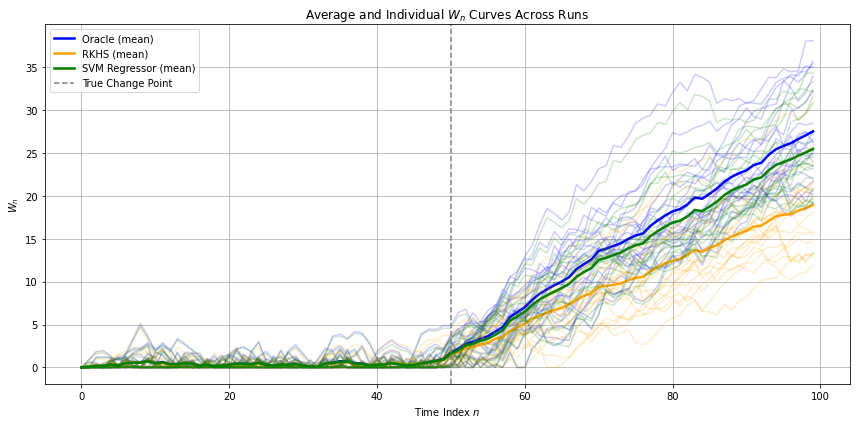

In [2]:
# Re-run the previous simulation to store W_n curves for all detectors
W_oracle_list = []
W_rkhs_list = []
W_svm_list = []

# Rerun with fewer trials for quick plotting
n_trials = 20
n_total = 100
changepoint = 50
threshold = 5.0
train_size = 300
sigma = 1.0
lambda_reg = 1e-2

f0_pdf = lambda x: norm.pdf(x, loc=0.0, scale=1.0)
f1_pdf = lambda x: norm.pdf(x, loc=1.0, scale=1.0)

for seed in range(n_trials):
    np.random.seed(seed)

    X_p = np.random.normal(1.0, 1.0, train_size)
    X_q = np.random.normal(0.0, 1.0, train_size)

    # Fit estimators
    rkhs_model = RKHSBasedCUSUM(threshold=threshold, sigma=sigma, lambda_reg=lambda_reg)
    rkhs_model.fit(X_p, X_q)

    svm_model = SVMBasedCUSUM(threshold=threshold)
    svm_model.fit(X_p, X_q)

    oracle = OracleCUSUM(f0_pdf, f1_pdf, threshold)

    # Generate stream with change
    stream = np.concatenate([
        np.random.normal(0.0, 1.0, changepoint),
        np.random.normal(1.0, 1.0, n_total - changepoint)
    ])

    W_oracle, _ = oracle.run(stream)
    W_rkhs, _ = rkhs_model.run(stream)
    W_svm, _ = svm_model.run(stream)

    W_oracle_list.append(W_oracle)
    W_rkhs_list.append(W_rkhs)
    W_svm_list.append(W_svm)

# Now replot the average and individual W_n curves
import matplotlib.pyplot as plt

W_oracle_array = np.vstack(W_oracle_list)
W_rkhs_array = np.vstack(W_rkhs_list)
W_svm_array = np.vstack(W_svm_list)

mean_W_oracle = W_oracle_array.mean(axis=0)
mean_W_rkhs = W_rkhs_array.mean(axis=0)
mean_W_svm = W_svm_array.mean(axis=0)

plt.figure(figsize=(12, 6))

for w in W_oracle_array:
    plt.plot(w, color='blue', alpha=0.2)
plt.plot(mean_W_oracle, color='blue', linewidth=2.5, label="Oracle (mean)")

for w in W_rkhs_array:
    plt.plot(w, color='orange', alpha=0.2)
plt.plot(mean_W_rkhs, color='orange', linewidth=2.5, label="RKHS (mean)")

for w in W_svm_array:
    plt.plot(w, color='green', alpha=0.2)
plt.plot(mean_W_svm, color='green', linewidth=2.5, label="SVM Regressor (mean)")

plt.axvline(changepoint, color='gray', linestyle='--', label='True Change Point')
plt.title("Average and Individual $W_n$ Curves Across Runs")
plt.xlabel("Time Index $n$")
plt.ylabel("$W_n$")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/SVM_Wn_multiruns.png", dpi=300, bbox_inches='tight')
plt.show()


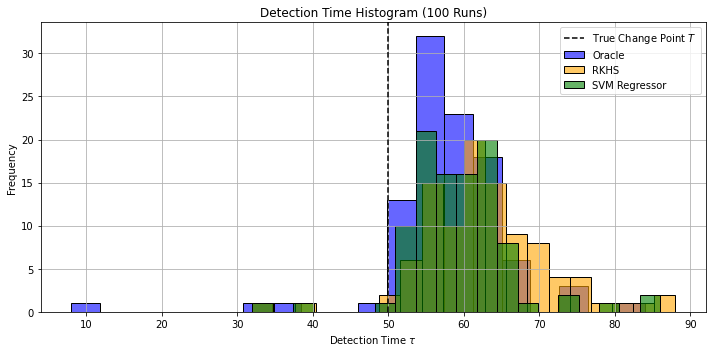

In [3]:
import seaborn as sns

# Re-run the simulation for 50 runs to collect detection times
n_runs = 100
delays_oracle, delays_rkhs, delays_svm = [], [], []
tau_oracle_all, tau_rkhs_all, tau_svm_all = [], [], []

for seed in range(n_runs):
    np.random.seed(seed)
    
    # Generate training data
    X_p = np.random.normal(1.0, 1.0, 300)
    X_q = np.random.normal(0.0, 1.0, 300)

    # Fit models
    rkhs_model = RKHSBasedCUSUM(threshold=5.0)
    rkhs_model.fit(X_p, X_q)

    svm_model = SVMBasedCUSUM(threshold=5.0)
    svm_model.fit(X_p, X_q)

    oracle_model = OracleCUSUM(f0_pdf=lambda x: norm.pdf(x, 0, 1),
                               f1_pdf=lambda x: norm.pdf(x, 1, 1),
                               threshold=5.0)

    # Generate stream with change at T
    changepoint = 50
    n_total = 300
    stream = np.concatenate([
        np.random.normal(0.0, 1.0, changepoint),
        np.random.normal(1.0, 1.0, n_total - changepoint)
    ])

    # Run all detectors
    _, tau_oracle = oracle_model.run(stream)
    _, tau_rkhs = rkhs_model.run(stream)
    _, tau_svm = svm_model.run(stream)

    if tau_oracle: tau_oracle_all.append(tau_oracle)
    if tau_rkhs: tau_rkhs_all.append(tau_rkhs)
    if tau_svm: tau_svm_all.append(tau_svm)

# Plot histograms of detection times (tau)
plt.figure(figsize=(10, 5))
sns.histplot(tau_oracle_all, bins=20, label='Oracle', color='blue', alpha=0.6)
sns.histplot(tau_rkhs_all, bins=20, label='RKHS', color='orange', alpha=0.6)
sns.histplot(tau_svm_all, bins=20, label='SVM Regressor', color='green', alpha=0.6)
plt.axvline(changepoint, color='black', linestyle='--', label='True Change Point $T$')
plt.xlabel("Detection Time $\\tau$")
plt.ylabel("Frequency")
plt.title("Detection Time Histogram (100 Runs)")
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/SVM_DD_histograms.png", dpi=300, bbox_inches='tight')
plt.show()


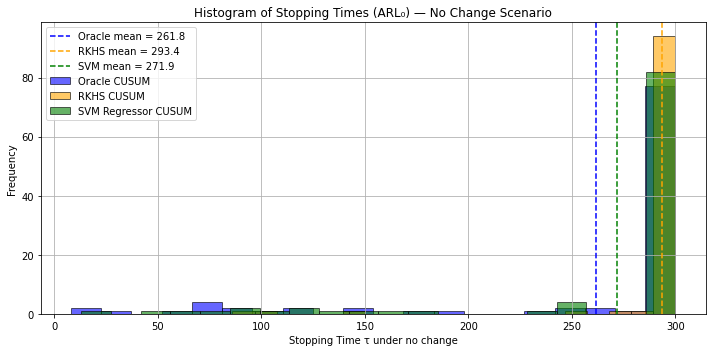

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.svm import SVR

# Oracle CUSUM
class CUSUM:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.b = threshold

    def run(self, x):
        W = np.zeros_like(x, dtype=float)
        tau = None
        for n in range(1, len(x)):
            llr = np.log(self.f1(x[n]) / self.f0(x[n]))
            W[n] = max(0, W[n-1] + llr)
            if tau is None and W[n] >= self.b:
                tau = n
        return W, tau

# SVM Regressor based CUSUM
class SVMRegressorCUSUM:
    def __init__(self, threshold=5.0):
        self.threshold = threshold
        self.model = SVR()

    def fit(self, X_p, X_q):
        X = np.concatenate([X_p, X_q])[:, None]
        y = np.concatenate([np.ones(len(X_p)), -np.ones(len(X_q))])
        self.model.fit(X, y)

    def run(self, stream):
        llrs = self.model.predict(stream[:, None])
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            W[n] = max(0, W[n-1] + llrs[n])
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# Run ARL₀ Experiment (no change case)
n_runs = 100
n_total = 300
threshold = 5.0

arl0_oracle = []
arl0_rkhs = []
arl0_svm = []

for seed in range(n_runs):
    np.random.seed(seed)
    stream = np.random.normal(0.0, 1.0, n_total)
    
    # Oracle
    f0 = lambda x: norm.pdf(x, 0.0, 1.0)
    f1 = lambda x: norm.pdf(x, 1.0, 1.0)
    oracle = CUSUM(f0, f1, threshold)
    _, tau_oracle = oracle.run(stream)
    arl0_oracle.append(tau_oracle if tau_oracle else n_total)

    # RKHS
    X_p = np.random.normal(1.0, 1.0, 300)
    X_q = np.random.normal(0.0, 1.0, 300)
    rkhs = RKHSBasedCUSUM(threshold=threshold)
    rkhs.fit(X_p, X_q)
    _, tau_rkhs = rkhs.run(stream)
    arl0_rkhs.append(tau_rkhs if tau_rkhs else n_total)

    # SVM Regressor
    svm = SVMRegressorCUSUM(threshold=threshold)
    svm.fit(X_p, X_q)
    _, tau_svm = svm.run(stream)
    arl0_svm.append(tau_svm if tau_svm else n_total)

# Plot histograms
plt.figure(figsize=(10, 5))
plt.hist(arl0_oracle, bins=20, alpha=0.6, label="Oracle CUSUM", edgecolor='black', color='blue')
plt.hist(arl0_rkhs, bins=20, alpha=0.6, label="RKHS CUSUM", edgecolor='black', color='orange')
plt.hist(arl0_svm, bins=20, alpha=0.6, label="SVM Regressor CUSUM", edgecolor='black', color='green')
plt.xlabel("Stopping Time τ under no change")
plt.ylabel("Frequency")
plt.title("Histogram of Stopping Times (ARL₀) — No Change Scenario")
plt.axvline(np.mean(arl0_oracle), color='blue', linestyle='--', label=f'Oracle mean = {np.mean(arl0_oracle):.1f}')
plt.axvline(np.mean(arl0_rkhs), color='orange', linestyle='--', label=f'RKHS mean = {np.mean(arl0_rkhs):.1f}')
plt.axvline(np.mean(arl0_svm), color='green', linestyle='--', label=f'SVM mean = {np.mean(arl0_svm):.1f}')
plt.legend()
plt.grid(True)
plt.tight_layout()
os.makedirs("../results", exist_ok=True)
plt.savefig("../results/SVM_ARL0_histograms.png", dpi=300, bbox_inches='tight')
plt.show()


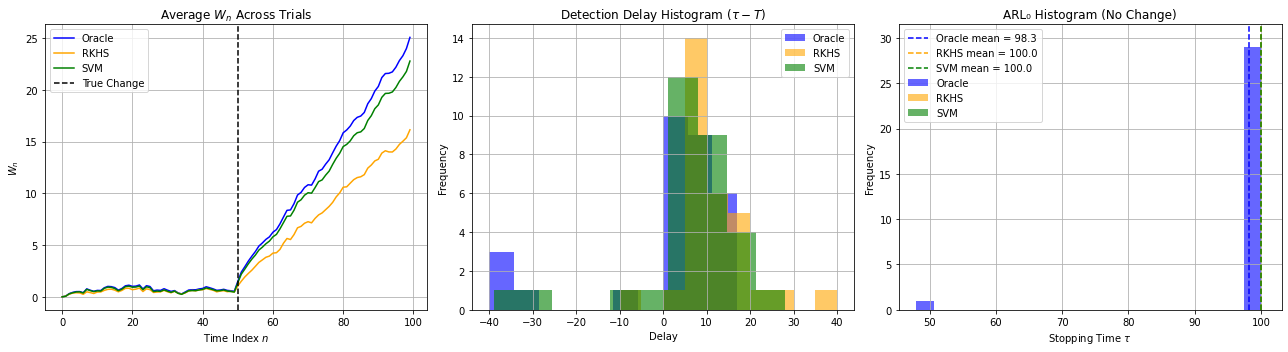

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.svm import SVR
from sklearn.metrics.pairwise import rbf_kernel
from scipy.optimize import minimize

# Oracle CUSUM
class OracleCUSUM:
    def __init__(self, f0_pdf, f1_pdf, threshold):
        self.f0 = f0_pdf
        self.f1 = f1_pdf
        self.threshold = threshold

    def run(self, stream):
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            llr = np.log(self.f1(stream[n]) / self.f0(stream[n]))
            W[n] = max(0, W[n - 1] + llr)
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# RKHS Estimator
class RKHSLikelihoodRatioEstimator:
    def __init__(self, sigma=1.0, lambda_reg=1e-2):
        self.sigma = sigma
        self.lambda_reg = lambda_reg
        self.alpha = None
        self.X_p = None

    def _compute_kernel_matrices(self, X_p, X_q):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K_PP = rbf_kernel(X_p[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        K_QP = rbf_kernel(X_q[:, np.newaxis], X_p[:, np.newaxis], gamma=gamma)
        return K_PP, K_QP

    def _loss(self, alpha, K_PP, K_QP):
        g_q = K_QP @ alpha
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        return np.mean(g_q) - np.mean(np.log(g_p)) + 0.5 * self.lambda_reg * (alpha @ K_PP @ alpha)

    def _grad(self, alpha, K_PP, K_QP):
        n_p = K_PP.shape[0]
        g_p = K_PP @ alpha
        g_p = np.clip(g_p, 1e-8, None)
        return np.mean(K_QP, axis=0) - (K_PP @ (1.0 / g_p)) / n_p + self.lambda_reg * (K_PP @ alpha)

    def fit(self, X_p, X_q):
        self.X_p = X_p
        K_PP, K_QP = self._compute_kernel_matrices(X_p, X_q)
        alpha0 = np.ones(len(X_p)) / len(X_p)
        result = minimize(
            fun=lambda a: self._loss(a, K_PP, K_QP),
            x0=alpha0,
            jac=lambda a: self._grad(a, K_PP, K_QP),
            method='L-BFGS-B',
            bounds=[(0, None)] * len(X_p)
        )
        self.alpha = result.x

    def predict_log(self, X):
        gamma = 1.0 / (2 * self.sigma ** 2)
        K = rbf_kernel(X[:, np.newaxis], self.X_p[:, np.newaxis], gamma=gamma)
        return np.log(np.clip(K @ self.alpha, 1e-8, None))

class RKHSBasedCUSUM:
    def __init__(self, threshold=5.0, sigma=1.0, lambda_reg=1e-2):
        self.threshold = threshold
        self.estimator = RKHSLikelihoodRatioEstimator(sigma=sigma, lambda_reg=lambda_reg)

    def fit(self, X_p, X_q):
        self.estimator.fit(X_p, X_q)

    def run(self, stream):
        log_llrs = self.estimator.predict_log(stream)
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            W[n] = max(0, W[n - 1] + log_llrs[n])
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# SVM Regressor CUSUM
class SVMBasedCUSUM:
    def __init__(self, threshold=5.0):
        self.threshold = threshold
        self.model = SVR()

    def fit(self, X_p, X_q):
        X = np.concatenate([X_p, X_q])[:, None]
        y = np.log(norm.pdf(X.ravel(), 1.0, 1.0) / norm.pdf(X.ravel(), 0.0, 1.0))
        self.model.fit(X, y)

    def run(self, stream):
        log_llrs = self.model.predict(stream[:, None])
        W = np.zeros(len(stream))
        tau = None
        for n in range(1, len(stream)):
            W[n] = max(0, W[n - 1] + log_llrs[n])
            if tau is None and W[n] >= self.threshold:
                tau = n
        return W, tau

# === EXPERIMENTS ===
n_trials = 20
n_total = 100
changepoint = 50
threshold = 5.0
train_size = 300

W_oracle_list, W_rkhs_list, W_svm_list = [], [], []

for seed in range(n_trials):
    np.random.seed(seed)
    X_p = np.random.normal(1.0, 1.0, train_size)
    X_q = np.random.normal(0.0, 1.0, train_size)
    stream = np.concatenate([
        np.random.normal(0.0, 1.0, changepoint),
        np.random.normal(1.0, 1.0, n_total - changepoint)
    ])

    rkhs = RKHSBasedCUSUM(threshold=threshold)
    rkhs.fit(X_p, X_q)
    svm = SVMBasedCUSUM(threshold=threshold)
    svm.fit(X_p, X_q)
    oracle = OracleCUSUM(lambda x: norm.pdf(x, 0, 1), lambda x: norm.pdf(x, 1, 1), threshold)

    W_oracle_list.append(oracle.run(stream)[0])
    W_rkhs_list.append(rkhs.run(stream)[0])
    W_svm_list.append(svm.run(stream)[0])

# Detection delay and ARL₀
n_runs = 30
delays_oracle, delays_rkhs, delays_svm = [], [], []
arl0_oracle, arl0_rkhs, arl0_svm = [], [], []

for seed in range(n_runs):
    np.random.seed(seed)
    X_p = np.random.normal(1.0, 1.0, train_size)
    X_q = np.random.normal(0.0, 1.0, train_size)

    # Streams
    stream_c = np.concatenate([
        np.random.normal(0.0, 1.0, changepoint),
        np.random.normal(1.0, 1.0, n_total - changepoint)
    ])
    stream_n = np.random.normal(0.0, 1.0, n_total)

    rkhs = RKHSBasedCUSUM(threshold=threshold)
    rkhs.fit(X_p, X_q)
    svm = SVMBasedCUSUM(threshold=threshold)
    svm.fit(X_p, X_q)
    oracle = OracleCUSUM(lambda x: norm.pdf(x, 0, 1), lambda x: norm.pdf(x, 1, 1), threshold)

    _, tau_o = oracle.run(stream_c)
    _, tau_r = rkhs.run(stream_c)
    _, tau_s = svm.run(stream_c)
    if tau_o is not None: delays_oracle.append(tau_o - changepoint)
    if tau_r is not None: delays_rkhs.append(tau_r - changepoint)
    if tau_s is not None: delays_svm.append(tau_s - changepoint)

    _, tau_o0 = oracle.run(stream_n)
    _, tau_r0 = rkhs.run(stream_n)
    _, tau_s0 = svm.run(stream_n)
    arl0_oracle.append(tau_o0 if tau_o0 is not None else n_total)
    arl0_rkhs.append(tau_r0 if tau_r0 is not None else n_total)
    arl0_svm.append(tau_s0 if tau_s0 is not None else n_total)

# === PLOTS ===
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# Average W_n
axs[0].set_title("Average $W_n$ Across Trials")
axs[0].plot(np.mean(W_oracle_list, axis=0), label="Oracle", color='blue')
axs[0].plot(np.mean(W_rkhs_list, axis=0), label="RKHS", color='orange')
axs[0].plot(np.mean(W_svm_list, axis=0), label="SVM", color='green')
axs[0].axvline(changepoint, linestyle='--', color='black', label="True Change")
axs[0].legend()
axs[0].set_xlabel("Time Index $n$")
axs[0].set_ylabel("$W_n$")
axs[0].grid(True)

# Detection Delay Histogram
axs[1].set_title("Detection Delay Histogram ($\\tau - T$)")
axs[1].hist(delays_oracle, alpha=0.6, label='Oracle', color='blue')
axs[1].hist(delays_rkhs, alpha=0.6, label='RKHS', color='orange')
axs[1].hist(delays_svm, alpha=0.6, label='SVM', color='green')
axs[1].legend()
axs[1].set_xlabel("Delay")
axs[1].set_ylabel("Frequency")
axs[1].grid(True)

# ARL₀ Histogram
axs[2].set_title("ARL₀ Histogram (No Change)")
axs[2].hist(arl0_oracle, bins=20, alpha=0.6, label="Oracle", color='blue')
axs[2].hist(arl0_rkhs, bins=20, alpha=0.6, label="RKHS", color='orange')
axs[2].hist(arl0_svm, bins=20, alpha=0.6, label="SVM", color='green')
axs[2].axvline(np.mean(arl0_oracle), color='blue', linestyle='--', label=f"Oracle mean = {np.mean(arl0_oracle):.1f}")
axs[2].axvline(np.mean(arl0_rkhs), color='orange', linestyle='--', label=f"RKHS mean = {np.mean(arl0_rkhs):.1f}")
axs[2].axvline(np.mean(arl0_svm), color='green', linestyle='--', label=f"SVM mean = {np.mean(arl0_svm):.1f}")
axs[2].legend()
axs[2].set_xlabel("Stopping Time $\\tau$")
axs[2].set_ylabel("Frequency")
axs[2].grid(True)

plt.tight_layout()
plt.show()
